# Week 5 — Descriptive Analytics
### *What happened?* Summarising and exploring the cleaned travel-review data
**SENG 42293 Big Data Analytics · LO3**

Descriptive analytics is the first and most used layer: it turns millions of rows into a handful of numbers and pictures a person can act on. It never predicts and never prescribes, but if it is wrong, everything after it is wrong.

**In this notebook:** central tendency and spread · distributions and shape · group aggregation · pivot tables · time trends · correlation (and its limits) · the **small-sample trap** in rankings · KPI dashboards · how it scales in Spark.

**Data:** `data/reviews_clean.csv` is the *gold* layer produced by the Pipeline Guide (cleaned, de-duplicated, with lexicon sentiment).

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
ACC, ACCL, CH, GREY = "#8b7355", "#c4b5a0", "#2a2a2a", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[ACC, "#2a2a2a", ACCL, "#b5651d", "#6b8e8e", GREY]),
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
RES = {}                      # key numbers, reused in the slides and notes
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130); plt.show()

In [2]:
reviews = pd.read_csv("data/reviews_clean.csv", parse_dates=["review_date"])
hotels = pd.read_csv("data/hotel_stats.csv", parse_dates=["last_review"])
print(reviews.shape, "| hotels:", hotels.shape)
reviews.head(3)

(17266, 19) | hotels: (295, 9)


,hotel_id,hotel_name,stars,review_id,user,rating,text,tags,helpful_votes,review_date,city,n_words,pos_hits,neg_hits,sentiment,label,year,month,weekday
0,H-1000,Royal Inn 0,4,H-1000-R000,u572,5.0,"Friendly staff, good value, highly recommended...",family,16.0,2023-08-17,Nuwara Eliya,8,4,0,0.50,positive,2023,2023-08,Thu
1,H-1000,Royal Inn 0,4,H-1000-R001,u903,4.0,"Highly recommended, peaceful location, great v...",NaN,13.0,2024-03-05,Nuwara Eliya,6,3,0,0.50,positive,2024,2024-03,Tue
2,H-1000,Royal Inn 0,4,H-1000-R002,u1379,2.5,"Friendly staff, standard hotel.",NaN,NaN,2025-02-20,Nuwara Eliya,4,1,0,0.25,positive,2025,2025-02,Thu


## 1. First look: structure, types, missing values
Every descriptive analysis starts by checking what you actually have.

In [3]:
display(reviews.dtypes.to_frame("dtype").join(reviews.isna().sum().rename("missing")).join(reviews.nunique().rename("distinct")))
rated = reviews.dropna(subset=["rating"]).copy()
print(f"rows: {len(reviews):,} | with a valid rating: {len(rated):,} ({len(rated)/len(reviews):.1%})")
RES["n_reviews"], RES["n_rated"] = len(reviews), len(rated)

,dtype,missing,distinct
hotel_id,object,0,295
hotel_name,object,0,295
stars,int64,0,4
review_id,object,0,17266
user,object,0,3955
rating,float64,2083,9
text,object,0,8495
tags,object,6925,259
helpful_votes,float64,8639,26
review_date,datetime64[ns],0,901


rows: 17,266 | with a valid rating: 15,183 (87.9%)


## 2. Central tendency and spread
| Measure | Use when | Weakness |
|---|---|---|
| Mean | symmetric data, need totals | pulled by outliers |
| Median | skewed data, robust summary | ignores magnitude of extremes |
| Mode | categorical or discrete data | may be non-unique |
| Std dev / variance | spread around the mean | assumes mean is meaningful |
| IQR (Q3-Q1) | robust spread | ignores tails |

In [4]:
r = rated["rating"]
summary = pd.Series({"count": r.count(), "mean": r.mean(), "median": r.median(), "mode": r.mode().iloc[0],
                     "std": r.std(), "min": r.min(), "Q1": r.quantile(.25), "Q3": r.quantile(.75),
                     "IQR": r.quantile(.75) - r.quantile(.25), "skew": r.skew(), "kurtosis": r.kurt()}).round(3)
display(summary.to_frame("rating"))
RES.update(mean=round(r.mean(), 3), median=float(r.median()), std=round(r.std(), 3), skew=round(r.skew(), 3),
           q1=float(r.quantile(.25)), q3=float(r.quantile(.75)))

,rating
count,15183.000
mean,3.598
median,3.500
mode,3.500
std,0.986
min,1.000
Q1,3.000
Q3,4.500
IQR,1.500
skew,-0.354


A **negative skew** (tail to the left) means the mean sits *below* the median: a few very low ratings pull it down. Always look at the picture:

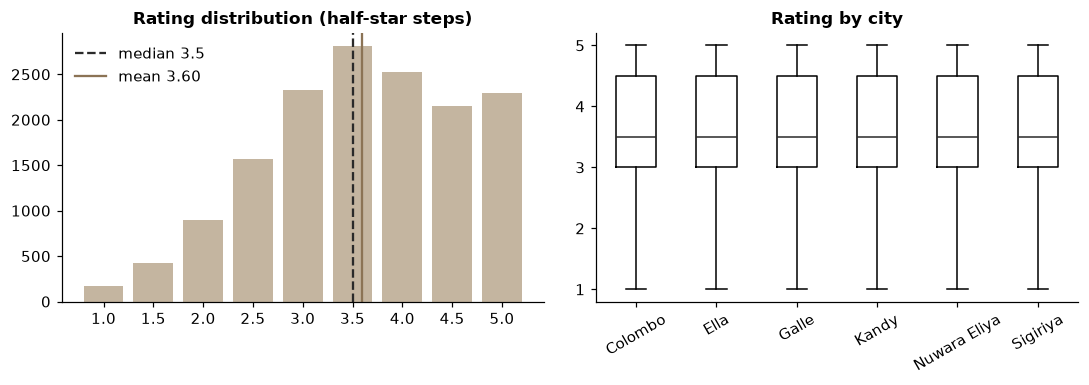

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
cnt = r.value_counts().sort_index()
ax[0].bar(cnt.index.astype(str), cnt.values, color=ACCL); ax[0].set_title("Rating distribution (half-star steps)")
ax[0].axvline(list(cnt.index).index(r.median()), color=CH, ls="--", label=f"median {r.median()}")
ax[0].axvline(r.mean() * 2 - 2, color=ACC, ls="-", label=f"mean {r.mean():.2f}"); ax[0].legend(frameon=False)
ax[1].boxplot([rated.loc[rated.city == c, "rating"] for c in sorted(rated.city.unique())], tick_labels=sorted(rated.city.unique()), vert=True)
ax[1].set_title("Rating by city"); ax[1].tick_params(axis="x", rotation=30)
save("w05_distribution")

**Exercise 1.** The mean line is drawn at `mean*2 - 2`. Why? *(Hint: the x-axis is categorical positions, not rating values.)*

## 3. Group aggregation: the workhorse of descriptive analytics
`groupby → aggregate` is the same idea as Spark's `groupBy().agg()`; only the engine changes.

In [6]:
by_city = (rated.groupby("city").agg(reviews=("rating", "size"), mean_rating=("rating", "mean"), median=("rating", "median"),
           std=("rating", "std"), pct_positive=("label", lambda s: (s == "positive").mean())).round(3).sort_values("mean_rating", ascending=False))
display(by_city)
RES["best_city"], RES["worst_city"] = by_city.index[0], by_city.index[-1]
RES["city_gap"] = round(by_city.mean_rating.iloc[0] - by_city.mean_rating.iloc[-1], 3)

,reviews,mean_rating,median,std,pct_positive
city,,,,,
Ella,2110,3.697,3.5,0.985,0.624
Galle,2471,3.670,3.5,0.991,0.610
Nuwara Eliya,3210,3.641,3.5,0.966,0.626
Kandy,2217,3.555,3.5,0.995,0.584
Sigiriya,2632,3.539,3.5,0.983,0.574
Colombo,2543,3.492,3.5,0.986,0.565


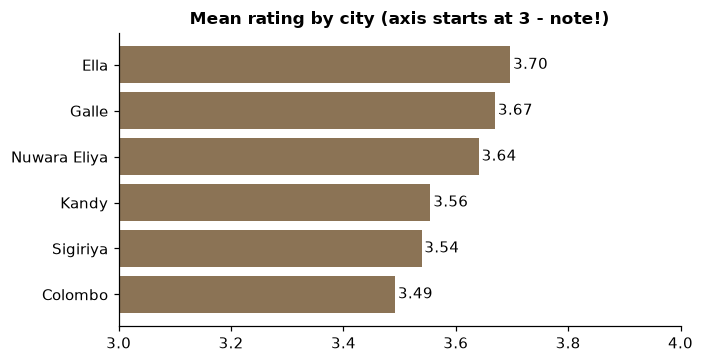

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
s = by_city["mean_rating"].sort_values()
ax.barh(s.index, s.values, color=ACC); ax.set_xlim(3, 4); ax.set_title("Mean rating by city (axis starts at 3 - note!)")
for i, v in enumerate(s.values): ax.text(v + .005, i, f"{v:.2f}", va="center")
save("w05_city_means")

> **Careful:** the axis starts at 3, which exaggerates differences. Week 12 returns to this. The city gap is only about 0.2 stars.

## 4. Pivot tables and heatmaps

stars,2,3,4,5
city,,,,
Colombo,3.52,3.52,3.56,3.27
Ella,3.67,3.67,3.73,3.70
Galle,3.80,3.78,3.38,3.59
Kandy,3.30,3.62,3.60,3.45
Nuwara Eliya,3.80,3.71,3.62,3.51
Sigiriya,3.49,3.60,3.48,3.53


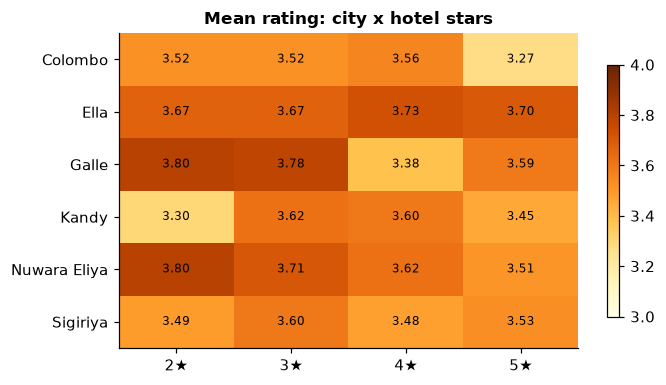

In [8]:
pv = rated.pivot_table(index="city", columns="stars", values="rating", aggfunc="mean").round(2)
display(pv)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
im = ax.imshow(pv.values, cmap="YlOrBr", aspect="auto", vmin=3, vmax=4)
ax.set_xticks(range(len(pv.columns)), [f"{c}★" for c in pv.columns]); ax.set_yticks(range(len(pv.index)), pv.index)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]): ax.text(j, i, f"{pv.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Mean rating: city x hotel stars"); plt.colorbar(im, ax=ax, shrink=.8); save("w05_heatmap")

## 5. Time trends
Aggregate to a regular period, then smooth to see the signal. (The last month is partial, so we drop it.)

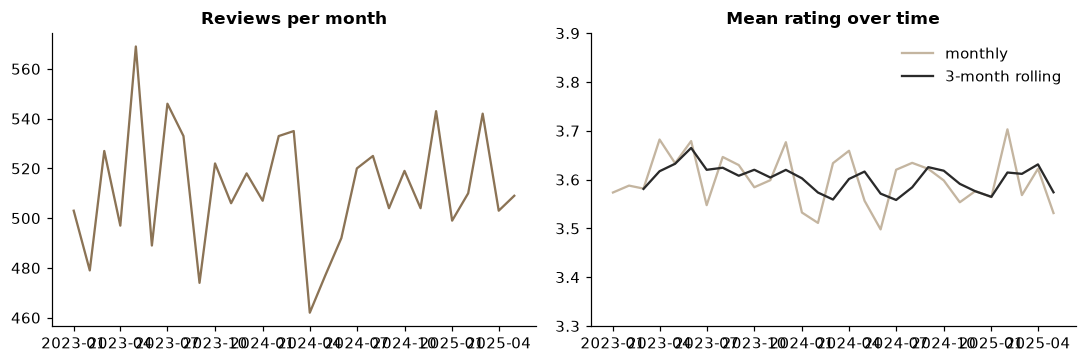

monthly mean-rating range: [np.float64(3.5), np.float64(3.7)]


In [9]:
monthly = rated.set_index("review_date").resample("MS").agg(n=("rating", "size"), mean_rating=("rating", "mean")).iloc[:-1]
monthly["rolling_3m"] = monthly["mean_rating"].rolling(3).mean()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(monthly.index, monthly["n"], color=ACC); ax[0].set_title("Reviews per month")
ax[1].plot(monthly.index, monthly["mean_rating"], color=ACCL, label="monthly"); ax[1].plot(monthly.index, monthly["rolling_3m"], color=CH, label="3-month rolling")
ax[1].set_ylim(3.3, 3.9); ax[1].legend(frameon=False); ax[1].set_title("Mean rating over time")
save("w05_trend")
RES["monthly_mean_rating_range"] = [round(monthly.mean_rating.min(), 2), round(monthly.mean_rating.max(), 2)]
print("monthly mean-rating range:", RES["monthly_mean_rating_range"])

Ask: is there a trend, a seasonal pattern, or only noise? With about 500 reviews a month, the monthly mean varies by roughly ±0.1 by chance alone. **Not every wiggle is a story.**

## 6. Correlation, and what it does not mean

,rating,sentiment,n_words,helpful_votes,stars
rating,1.000,0.863,-0.108,-0.002,-0.047
sentiment,0.863,1.000,-0.106,-0.013,-0.034
n_words,-0.108,-0.106,1.000,0.010,-0.005
helpful_votes,-0.002,-0.013,0.010,1.000,0.004
stars,-0.047,-0.034,-0.005,0.004,1.000


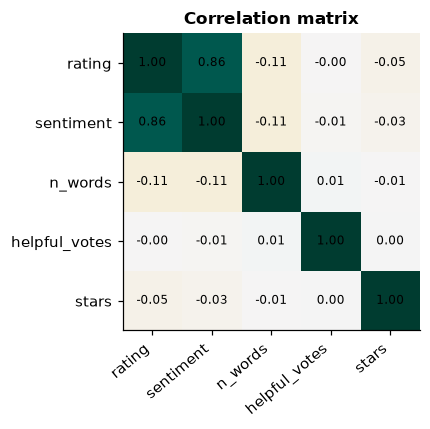

In [10]:
cols = ["rating", "sentiment", "n_words", "helpful_votes", "stars"]
corr = rated[cols].corr().round(3)
display(corr)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr.values, cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=40, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)): ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation matrix"); save("w05_corr")
RES["corr_rating_sentiment"] = float(corr.loc["rating", "sentiment"]); RES["corr_rating_stars"] = float(corr.loc["rating", "stars"])

* `rating` and `sentiment` correlate strongly because the synthetic review text was generated from the rating. Real text is far noisier.
* `rating` and `stars` (the hotel's official class) are almost uncorrelated here: a 5-star hotel is not automatically rated higher.
* **Correlation is not causation**, and Pearson's *r* only measures *linear* association. Plot before you trust a number.

## 7. The small-sample trap in rankings
Who are the 'best' hotels? Ranking by raw mean rating rewards hotels with *few* reviews, because small samples are noisy.

In [11]:
g = rated.groupby(["hotel_id", "hotel_name", "city"]).agg(n=("rating", "size"), mean_rating=("rating", "mean")).reset_index()
naive = g.sort_values("mean_rating", ascending=False).head(10)
print("Naive top 10 - review counts:", naive.n.tolist())
# Bayesian (shrinkage) average: pull small samples toward the global mean
m = 20; C = rated.rating.mean()
g["bayes"] = (g.n * g.mean_rating + m * C) / (g.n + m)
robust = g.sort_values("bayes", ascending=False).head(10)
print("Bayesian top 10 - review counts:", robust.n.tolist())
RES["naive_top10_median_n"], RES["bayes_top10_median_n"] = float(naive.n.median()), float(robust.n.median())
display(robust[["hotel_name", "city", "n", "mean_rating", "bayes"]].round(3))

Naive top 10 - review counts: [57, 27, 50, 33, 66, 67, 72, 49, 46, 35]
Bayesian top 10 - review counts: [57, 66, 67, 50, 72, 71, 27, 49, 59, 33]


,hotel_name,city,n,mean_rating,bayes
48,Hilltop Resort 50,Nuwara Eliya,57,4.447,4.227
83,Palm Residency 86,Galle,66,4.303,4.139
7,Royal Lodge 7,Nuwara Eliya,67,4.269,4.115
235,Palm Resort 240,Ella,50,4.310,4.107
152,Sunrise Inn 156,Galle,72,4.243,4.103
238,Palm Inn 243,Ella,71,4.211,4.077
222,Royal Villa 227,Galle,27,4.426,4.074
251,Palm Residency 256,Ella,49,4.235,4.050
6,Sunrise Resort 6,Galle,59,4.186,4.038
260,Royal Resort 265,Ella,33,4.303,4.037


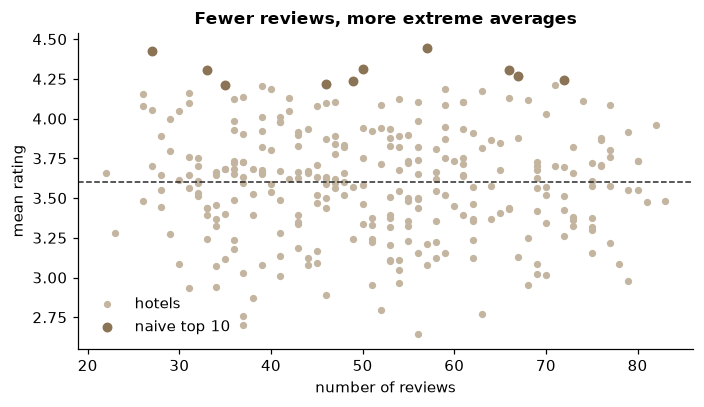

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter(g.n, g.mean_rating, s=14, color=ACCL, label="hotels")
ax.scatter(naive.n, naive.mean_rating, s=30, color=ACC, label="naive top 10"); ax.axhline(C, color=CH, ls="--", lw=1)
ax.set_xlabel("number of reviews"); ax.set_ylabel("mean rating"); ax.set_title("Fewer reviews, more extreme averages"); ax.legend(frameon=False)
save("w05_funnel_plot")

The scatter forms a **funnel**: low-*n* hotels spread widely, high-*n* hotels cluster near the global mean. In this dataset every hotel has at least ~30 reviews, so the effect is mild. Real platforms have hotels with 1-5 reviews, where it is dramatic. Let us simulate that: pretend each hotel only had a **random 3 to 60 reviews** (as on a real platform) and see how well each ranking recovers the true top 10 (from all reviews).

In [13]:
rng = np.random.default_rng(0)
true_top = set(g.sort_values("bayes", ascending=False).head(10).hotel_id)       # best estimate of the truth: all reviews
overlap_naive, overlap_bayes = [], []
for rep in range(200):
    samp = rated.groupby("hotel_id", group_keys=False).apply(lambda d: d.sample(min(len(d), int(rng.integers(3, 61))), random_state=int(rng.integers(1e9))))
    gs = samp.groupby("hotel_id").rating.agg(["size", "mean"])
    gs["bayes"] = (gs["size"] * gs["mean"] + 20 * C) / (gs["size"] + 20)
    overlap_naive.append(len(true_top & set(gs["mean"].nlargest(10).index)))
    overlap_bayes.append(len(true_top & set(gs["bayes"].nlargest(10).index)))
print(f"hotels also in the true top 10 (mean of 200 trials): naive = {np.mean(overlap_naive):.2f}, Bayesian = {np.mean(overlap_bayes):.2f}")
RES["overlap_naive_sparse"], RES["overlap_bayes_sparse"] = round(float(np.mean(overlap_naive)), 2), round(float(np.mean(overlap_bayes)), 2)

hotels also in the true top 10 (mean of 200 trials): naive = 5.31, Bayesian = 5.89


When review counts vary, the naive ranking is fooled by lucky small samples while the shrinkage ranking holds up better. Note that when every hotel has the *same* n, shrinkage cannot change the order at all. The honest message: **a ranking is only as good as the evidence behind it**, so always show the review count next to the score.

## 8. A KPI dashboard (one picture for decision makers)

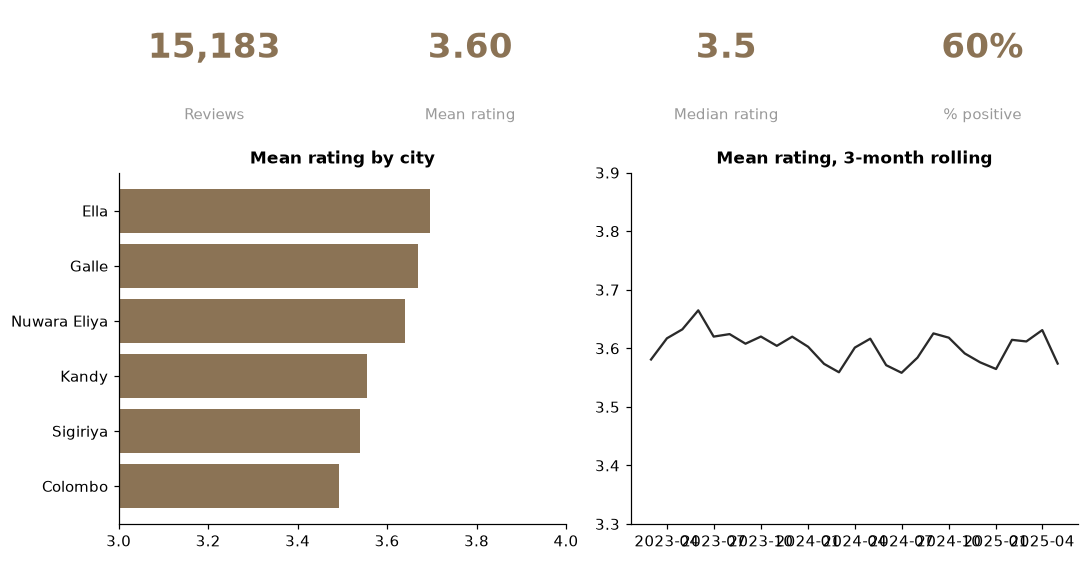

In [14]:
fig = plt.figure(figsize=(10, 5.2)); gs = fig.add_gridspec(2, 4, height_ratios=[.35, 1])
kpis = [("Reviews", f"{len(rated):,}"), ("Mean rating", f"{r.mean():.2f}"), ("Median rating", f"{r.median():.1f}"), ("% positive", f"{(rated.label=='positive').mean():.0%}")]
for i, (k, v) in enumerate(kpis):
    a = fig.add_subplot(gs[0, i]); a.axis("off"); a.text(.5, .62, v, ha="center", fontsize=22, color=ACC, weight="bold"); a.text(.5, .12, k, ha="center", fontsize=10, color=GREY)
a = fig.add_subplot(gs[1, :2]); a.barh(s.index, s.values, color=ACC); a.set_xlim(3, 4); a.set_title("Mean rating by city")
a = fig.add_subplot(gs[1, 2:]); a.plot(monthly.index, monthly["rolling_3m"], color=CH); a.set_title("Mean rating, 3-month rolling"); a.set_ylim(3.3, 3.9)
save("w05_dashboard")

## 9. Descriptive analytics at scale (Spark)
The same questions, answered on a cluster. Only the small result comes back to the driver.

In [15]:
import sys; os.environ["PYSPARK_PYTHON"] = sys.executable
from pyspark.sql import SparkSession, functions as F
spark = SparkSession.builder.master("local[*]").config("spark.ui.enabled", "false").getOrCreate(); spark.sparkContext.setLogLevel("ERROR")
sdf = spark.read.csv("data/reviews_clean.csv", header=True, inferSchema=True).filter(F.col("rating").isNotNull())
q = sdf.approxQuantile("rating", [.25, .5, .75], 0.01)
print("approx quantiles (Spark):", q, "| exact (pandas):", [r.quantile(x) for x in (.25, .5, .75)])
sdf.groupBy("city").agg(F.count("*").alias("n"), F.round(F.avg("rating"), 3).alias("mean")).orderBy(F.desc("mean")).show()
sdf.stat.corr("rating", "sentiment")

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1

26/10/13 08:35:59 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/13 08:35:59 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/13 08:35:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


approx quantiles (Spark): [3.0, 3.5, 4.5] | exact (pandas): [np.float64(3.0), np.float64(3.5), np.float64(4.5)]


+------------+----+-----+
|        city|   n| mean|
+------------+----+-----+
|        Ella|2110|3.697|
|       Galle|2471| 3.67|
|Nuwara Eliya|3210|3.641|
|       Kandy|2217|3.555|
|    Sigiriya|2632|3.539|
|     Colombo|2543|3.492|
+------------+----+-----+



0.8630118882985345

| pandas | Spark | Note |
|---|---|---|
| `df.describe()` | `df.describe()` / `summary()` | Spark computes it in parallel |
| `quantile` | `approxQuantile` | approximate, avoids a full sort |
| `groupby().agg()` | `groupBy().agg()` | wide transformation: shuffle |
| `corr()` | `stat.corr` | pairs only |
| `plot` | collect the *small* result, then plot | never `collect()` raw data |

In [16]:
spark.stop()
RES["spark_q"] = q
json.dump(RES, open("results/w05.json", "w"), indent=1); print(RES)

{'n_reviews': 17266, 'n_rated': 15183, 'mean': np.float64(3.598), 'median': 3.5, 'std': np.float64(0.986), 'skew': np.float64(-0.354), 'q1': 3.0, 'q3': 4.5, 'best_city': 'Ella', 'worst_city': 'Colombo', 'city_gap': np.float64(0.205), 'monthly_mean_rating_range': [np.float64(3.5), np.float64(3.7)], 'corr_rating_sentiment': 0.863, 'corr_rating_stars': -0.047, 'naive_top10_median_n': 49.5, 'bayes_top10_median_n': 58.0, 'overlap_naive_sparse': 5.31, 'overlap_bayes_sparse': 5.89, 'spark_q': [3.0, 3.5, 4.5]}


## 10. Exercises
1. Which city has the *highest variability* of ratings? Is it also the lowest-rated?
2. Re-do the pivot with `median` instead of `mean`. Does the story change?
3. Pick `m=5` and `m=100` in the Bayesian average. How does the top 10 change, and why?
4. Write a one-paragraph **insight** for a hotel owner using only this notebook's numbers. Which numbers would you *not* quote, and why?